<a href="https://colab.research.google.com/github/nehavijay21/yuva_intern/blob/main/Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
df = pd.read_csv(url)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print('Shape (rows, columns):', df.shape)
print()
df.info()

Shape (rows, columns): (891, 15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [4]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.describe(include='object')

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct}).query('missing_count > 0')

,missing_count,missing_%
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22


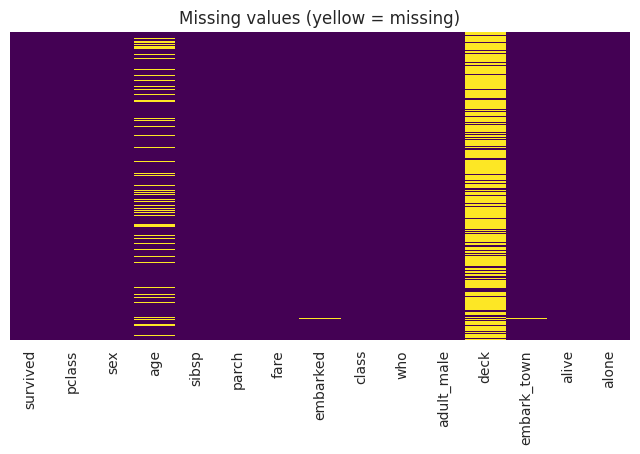

In [7]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing values (yellow = missing)')
plt.show()

In [8]:
df = df.drop(columns=['deck'])

print('Age mean  :', round(df['age'].mean(), 2))
print('Age median:', df['age'].median())

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

print()
print('Missing values left:', df.isnull().sum().sum())

Age mean  : 29.7
Age median: 28.0

Missing values left: 0


In [9]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Duplicate rows: 116
Shape after removing duplicates: (775, 14)


In [10]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


age: bounds = (-1.50, 58.50), outliers = 27
fare: bounds = (-31.17, 73.42), outliers = 102


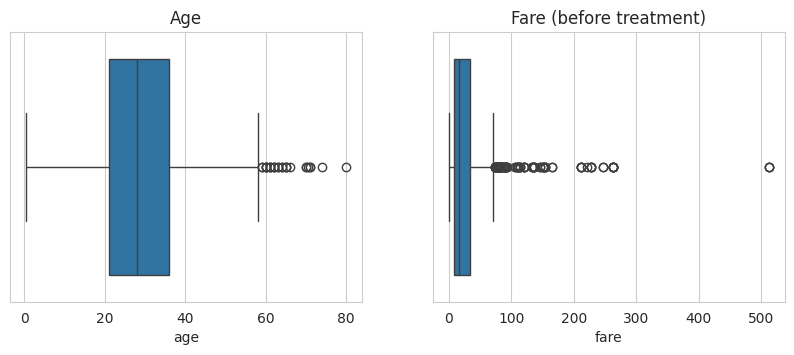

In [11]:
def iqr_bounds(series):
    q1, q3 = np.percentile(series, [25, 75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ['age', 'fare']:
    low, high = iqr_bounds(df[col])
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f'{col}: bounds = ({low:.2f}, {high:.2f}), outliers = {n_out}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=df['age'], ax=ax[0]); ax[0].set_title('Age')
sns.boxplot(x=df['fare'], ax=ax[1]); ax[1].set_title('Fare (before treatment)')
plt.show()

Max fare after capping: 73.42


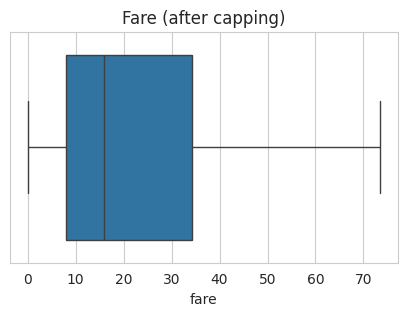

In [12]:
low, high = iqr_bounds(df['fare'])
df['fare'] = np.clip(df['fare'], low, high)
print('Max fare after capping:', round(df['fare'].max(), 2))

plt.figure(figsize=(5, 3))
sns.boxplot(x=df['fare'])
plt.title('Fare (after capping)')
plt.show()

In [13]:
print('Overall survival rate:', round(df['survived'].mean() * 100, 2), '%')
df['survived'].value_counts()

Overall survival rate: 41.29 %


,count
survived,
0,455
1,320


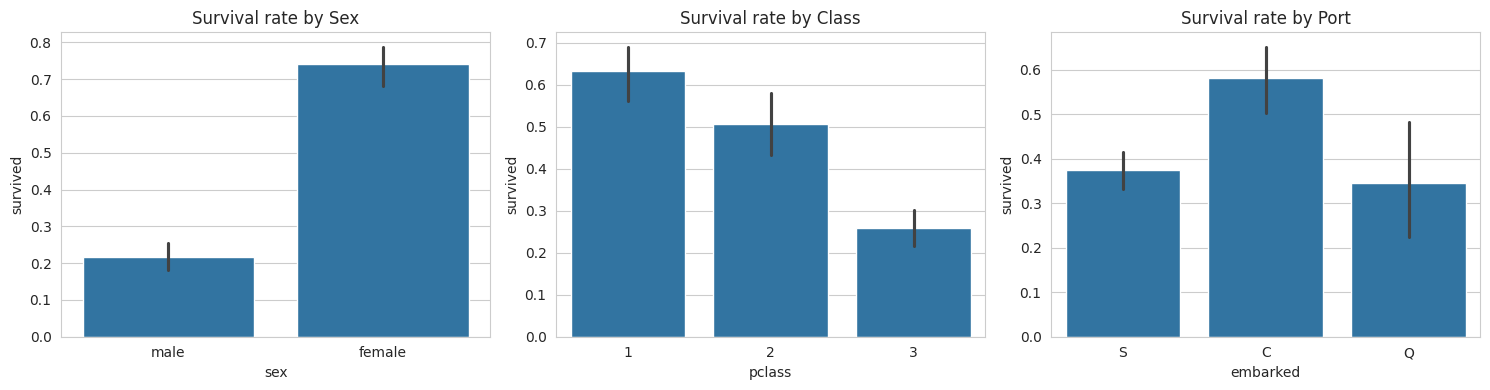

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x='sex', y='survived', data=df, ax=ax[0]); ax[0].set_title('Survival rate by Sex')
sns.barplot(x='pclass', y='survived', data=df, ax=ax[1]); ax[1].set_title('Survival rate by Class')
sns.barplot(x='embarked', y='survived', data=df, ax=ax[2]); ax[2].set_title('Survival rate by Port')
plt.tight_layout()
plt.show()

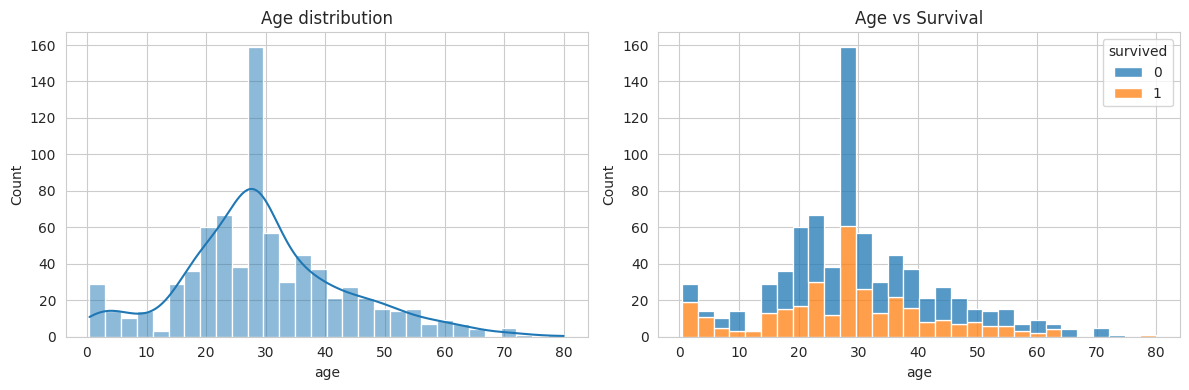

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['age'], bins=30, kde=True, ax=ax[0]); ax[0].set_title('Age distribution')
sns.histplot(data=df, x='age', hue='survived', bins=30, multiple='stack', ax=ax[1]); ax[1].set_title('Age vs Survival')
plt.tight_layout()
plt.show()

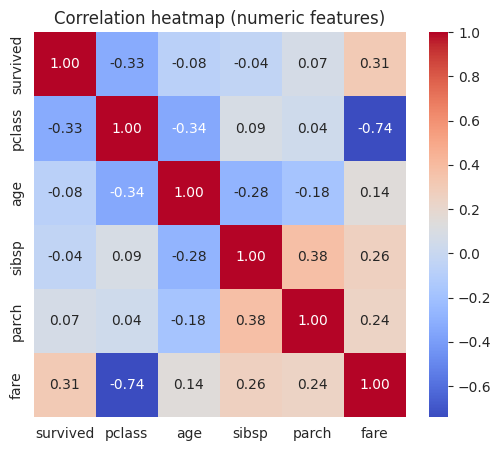

In [16]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap (numeric features)')
plt.show()

In [17]:
drop_cols = ['alive', 'class', 'embark_town', 'who', 'adult_male', 'alone']
df = df.drop(columns=drop_cols)
print('Remaining columns:', list(df.columns))

Remaining columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


In [18]:
df['family_size'] = df['sibsp'] + df['parch'] + 1
df[['sibsp', 'parch', 'family_size']].head()

,sibsp,parch,family_size
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [19]:
df['sex'] = df['sex'].map({'male': 0, 'female': 1})

df = pd.get_dummies(df, columns=['embarked'], drop_first=True, dtype=int)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,family_size,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,2,0,1
1,1,1,1,38.0,1,0,71.2833,2,0,0
2,1,3,1,26.0,0,0,7.9250,1,0,1
3,1,1,1,35.0,1,0,53.1000,2,0,1
4,0,3,0,35.0,0,0,8.0500,1,0,1


In [20]:
num_cols = ['age', 'fare', 'family_size']

# Min-Max
mm = MinMaxScaler()
df_minmax = df.copy()
df_minmax[num_cols] = mm.fit_transform(df[num_cols])

# Standardization
ss = StandardScaler()
df_std = df.copy()
df_std[num_cols] = ss.fit_transform(df[num_cols])

print('--- Min-Max (range check) ---')
print(df_minmax[num_cols].agg(['min', 'max']).round(2))
print()
print('--- Standardized (mean ~ 0, std ~ 1) ---')
print(df_std[num_cols].agg(['mean', 'std']).round(2))

--- Min-Max (range check) ---
     age  fare  family_size
min  0.0   0.0          0.0
max  1.0   1.0          1.0

--- Standardized (mean ~ 0, std ~ 1) ---
      age  fare  family_size
mean  0.0  -0.0         -0.0
std   1.0   1.0          1.0


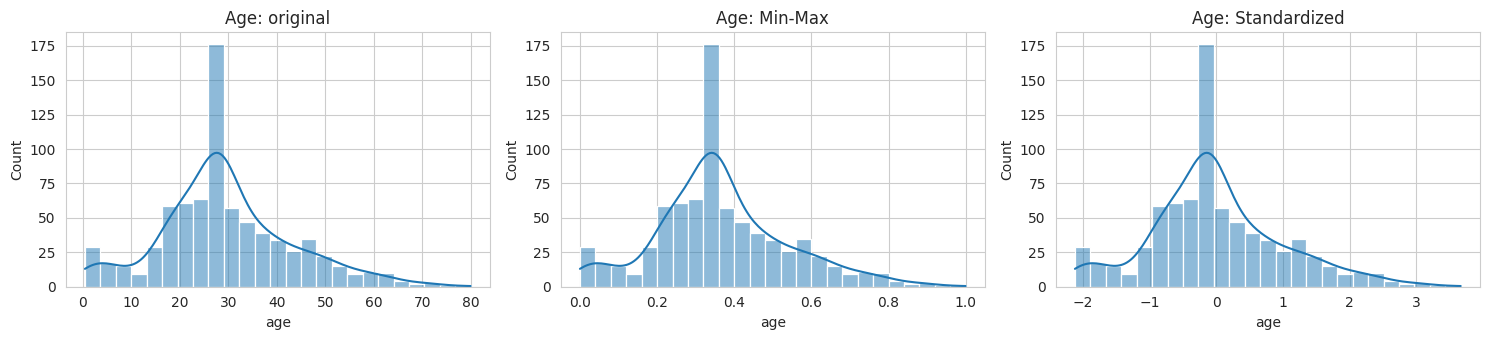

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(df['age'], kde=True, ax=ax[0]); ax[0].set_title('Age: original')
sns.histplot(df_minmax['age'], kde=True, ax=ax[1]); ax[1].set_title('Age: Min-Max')
sns.histplot(df_std['age'], kde=True, ax=ax[2]); ax[2].set_title('Age: Standardized')
plt.tight_layout()
plt.show()

## Step 10: Final Dataset & Save

In [22]:
final_df = df_std.copy()
print('Final shape:', final_df.shape)
print('Missing values:', final_df.isnull().sum().sum())
print('All numeric?  :', all(np.issubdtype(t, np.number) for t in final_df.dtypes))
final_df.head()

Final shape: (775, 10)
Missing values: 0
All numeric?  : True


,survived,pclass,sex,age,sibsp,parch,fare,family_size,embarked_Q,embarked_S
0,0,3,0,-0.551060,1,0,-0.846218,0.033066,0,1
1,1,1,1,0.611945,1,0,1.955092,0.033066,0,0
2,1,3,1,-0.260308,0,0,-0.816688,-0.624008,0,1
3,1,1,1,0.393881,1,0,1.159615,0.033066,0,1
4,0,3,0,0.393881,0,0,-0.811220,-0.624008,0,1


In [23]:
final_df.to_csv('titanic_cleaned.csv', index=False)
print('Saved: titanic_cleaned.csv')

Saved: titanic_cleaned.csv
